# 第 09 关：离开原样本

**本关要回答的问题：** 五因子模型是用 1963–2013 年的数据提出和检验的。换到论文之后的年份、换一批没有参与模型设计的资产，它的表现还好吗？

### 为什么要做样本外检验？
研究者在同一份数据上反复尝试不同的变量和设定，总能找到一些在这份数据上碰巧有效的模型，这叫**数据挖掘**或**过拟合**。检验的办法是看模型在**没有参与建模的数据**上表现如何：
- **留出期（holdout）**：FF2015 的样本截止于 2013-12。2014-01 至 2025-12 这 144 个月的数据在建模时还不存在，是天然的样本外期间。
- **另一类资产**：30 个行业组合按公司所属行业分组，与规模、B/M 等因子特征的排序无关，模型并不是为它们"量身定做"的。

研究设计在看到结果之前就固定下来：期间、资产和模型都不随结果调整。

### 两个实验
- **实验 A：分期重新估计**。在原样本和留出期各自跑一遍定价回归，回答"模型能否解释这一时期的平均收益"。
- **实验 B：冻结预测**。只用原样本估计 β 和因子的平均收益，算出每个组合的预期收益，再与留出期的实际平均收益比较。这更接近"站在 2013 年底用模型做预测"。

说明：留出期的数据是今天下载的修订版，也没有计算换手和交易成本，所以本关检验的是模型在新样本中的稳定性，而不是一个 2014 年就能实际执行的交易回测。

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "course.py").exists()), None)
if ROOT is None:
    raise RuntimeError("请在 asset_pricing_quest 项目或其 notebooks 文件夹中启动 Notebook。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from course import load_returns, style, save_table, paper_note, build_ff5
from analysis import fit_models, model_summary

style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 24)

In [2]:
display(Markdown(paper_note("ff2015")))

**论文对照：** [Fama & French (2015), A five-factor asset pricing model](../papers/ff2015_primary_reference.pdf)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 固定比较对象与期间
两个时期：原样本 1963-07 至 2013-12（606 个月），留出期 2014-01 至 2025-12（144 个月）。两类测试资产：25 个规模×B/M 组合和 30 个行业组合。行业组合的成分随时间变化（公司会上市、退市、改变行业），我们直接使用 French 每月公布的组合收益，这些收益自然反映了当时的成分。

In [3]:
PERIODS = {"原样本 1963-2013": ("1963-07", "2013-12"),
           "留出期 2014-2025": ("2014-01", "2025-12")}
ASSETS = {"Size × B/M (25)": "bm25", "Industries (30)": "industry30"}
names3 = ["Mkt-RF", "SMB", "HML"]
names5 = [*names3, "RMW", "CMA"]
display(pd.DataFrame([{"时期": label, "开始": start, "结束": end,
                       "预期月份数": len(pd.period_range(start, end, freq="M"))}
                      for label, (start, end) in PERIODS.items()]))

,时期,开始,结束,预期月份数
0,原样本 1963-2013,1963-07,2013-12,606
1,留出期 2014-2025,2014-01,2025-12,144


## 2. 实验 A：在每个时期内重新检验
对两个时期分别估计暴露和 α，比较 FF3 standard 与 FF5。两个时期的参数各自估计，没有用前一期去预测后一期。表中 `T` 是月份数，`N` 是组合数，其余列含义同第 05、08 关。

读表提示：留出期只有 144 个月，约为原样本的四分之一，统计检验力低得多。同样大小的 α，在短样本中更难显著，所以不要直接比较两个时期的 p 值高低，更应该比较 α 的大小。

In [4]:
comparisons = []
for period_label, (start, end) in PERIODS.items():
    ff3 = load_returns("ff3", start, end)
    ff5 = load_returns("ff5", start, end)
    assert ff3.index.equals(ff5.index)
    assert len(ff5) == len(pd.period_range(start, end, freq="M"))
    assert np.allclose(ff3["RF"], ff5["RF"])
    models = {"FF3 standard": ff3[names3], "FF5": ff5[names5]}
    for label, key in ASSETS.items():
        returns = load_returns(key, start, end)
        assert returns.index.equals(ff5.index)
        excess = returns.sub(ff5["RF"], axis=0)
        result = model_summary(excess, models).reset_index(names="model")
        result["period"], result["asset_set"] = period_label, label
        comparisons.append(result)
within_period = pd.concat(comparisons, ignore_index=True).set_index(["period", "asset_set", "model"])
fields = ["mean_abs_alpha_pct_month", "mean_r2", "grs_stat", "grs_pvalue", "T", "N"]
display(within_period[fields].style.format(precision=4,
    formatter={"grs_pvalue": "{:.3g}", "T": "{:.0f}", "N": "{:.0f}"}))
save_table(within_period, "09_reestimated_period_pricing_tests")

WindowsPath('E:/Eth data/asset_pricing_quest/results/09_reestimated_period_pricing_tests.csv')

**怎么读：**
- **规模×B/M 组合**：留出期的平均绝对 α（约 0.11 %/月）与原样本（约 0.10 %/月）相近，GRS 不再拒绝。但留出期样本短、检验力弱，"不再拒绝"不能读成"模型变好了"。
- **行业组合**：两个模型的误差都大得多（约 0.20–0.27 %/月），平均 R² 只有约 0.62–0.66。而且无论在哪个时期，五因子的平均绝对 α 都没有比三因子更小。行业组合不是按因子特征排序的，这说明模型的解释力在很大程度上依赖测试资产的选择。

## 3. 实验 B：用原样本冻结的模型预测留出期
只用原样本（训练期）估计每个组合的暴露 $\hat\beta_{i,\mathrm{train}}$ 和因子的平均收益 $\bar f_{\mathrm{train}}$，按模型（令 α = 0）算出预期月超额收益：

$$
\widehat{E}[R_i^e]=\hat{\beta}_{i,\mathrm{train}}'\,\bar{f}_{\mathrm{train}}.
$$

然后与留出期每个组合的实际平均超额收益比较。预测在训练期结束时就"冻结"了，不使用任何留出期的信息。

评价指标（单位 %/月）：
- `mae_pct_month`：平均绝对预测误差；
- `rmse_pct_month`：预测误差的均方根，对大误差更敏感；
- `mean_error_pct_month`：平均误差（实际 − 预测），为正表示模型整体低估了留出期的收益。

预测误差有三个来源：β 在两个时期之间变了；因子的平均收益（风险溢价）变了；144 个月的实际平均收益本身也有很大的抽样噪声。

In [5]:
train_start, train_end = PERIODS["原样本 1963-2013"]
test_start, test_end = PERIODS["留出期 2014-2025"]
train3 = load_returns("ff3", train_start, train_end)
train5 = load_returns("ff5", train_start, train_end)
test5 = load_returns("ff5", test_start, test_end)
train_models = {"FF3 standard": train3[names3], "FF5": train5[names5]}
prediction_frames, scores = {}, []
for label, key in ASSETS.items():
    train_returns = load_returns(key, train_start, train_end)
    test_returns = load_returns(key, test_start, test_end)
    assert train_returns.index.equals(train5.index)
    assert test_returns.index.equals(test5.index)
    assert train_returns.columns.equals(test_returns.columns)
    train_excess = train_returns.sub(train5["RF"], axis=0)
    observed = test_returns.sub(test5["RF"], axis=0).mean()
    for model_name, factors in train_models.items():
        fit_table, _ = fit_models(train_excess, factors)
        beta_columns = ["beta_" + name for name in factors]
        predicted = pd.Series(fit_table[beta_columns].to_numpy(dtype=float) @ factors.mean().to_numpy(dtype=float),
                              index=fit_table.index)
        observed_for_model = observed.reindex(predicted.index)
        error = observed_for_model - predicted
        frame = pd.DataFrame({"predicted_pct_month": predicted*100,
                              "observed_pct_month": observed_for_model*100,
                              "prediction_error_pct_month": error*100})
        prediction_frames[(label, model_name)] = frame
        scores.append({"asset_set": label, "model": model_name,
                       "mae_pct_month": error.abs().mean()*100,
                       "rmse_pct_month": np.sqrt(np.mean(error**2))*100,
                       "mean_error_pct_month": error.mean()*100})
prediction_scores = pd.DataFrame(scores).set_index(["asset_set", "model"])
display(prediction_scores.round(4))
save_table(prediction_scores, "09_frozen_expected_return_prediction_scores")
for (label, model_name), frame in prediction_frames.items():
    key = "bm25" if "B/M" in label else "industry30"
    model_key = "ff3" if "FF3" in model_name else "ff5"
    save_table(frame, f"09_frozen_predictions_{key}_{model_key}")

mae_pct_month  rmse_pct_month  \
asset_set       model                                         
Size × B/M (25) FF3 standard         0.2127          0.2905   
                FF5                  0.2077          0.2890   
Industries (30) FF3 standard         0.3570          0.4711   
                FF5                  0.3759          0.5252   

                              mean_error_pct_month  
asset_set       model                               
Size × B/M (25) FF3 standard                0.0563  
                FF5                         0.0433  
Industries (30) FF3 standard                0.1920  
                FF5                         0.0637

**怎么读：** 在规模×B/M 组合上，两个模型的冻结预测误差几乎相同（MAE 约 0.21 %/月）。在行业组合上，FF5 的 MAE 和 RMSE 反而更大，但平均误差更接近零：FF3 整体低估了留出期的行业收益约 0.19 %/月，FF5 只低估约 0.06 %/月。不同指标给出的排名不同，这正是需要同时报告多个指标的原因。

下图把 25 个规模×B/M 组合的预测（横轴）与留出期实际均值（纵轴）画在一起，点越靠近 45° 线，预测越准。

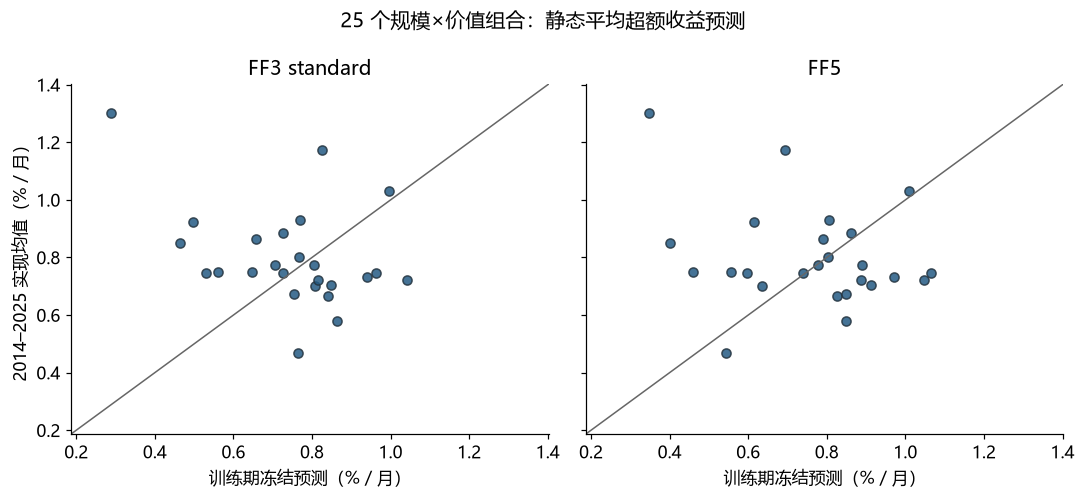

In [6]:
frames = [prediction_frames[("Size × B/M (25)", name)] for name in train_models]
all_values = np.concatenate([frame[["predicted_pct_month", "observed_pct_month"]].to_numpy(dtype=float).ravel()
                             for frame in frames])
lo, hi = all_values.min(), all_values.max()
pad = max((hi-lo)*0.1, 0.02)
limits = [lo-pad, hi+pad]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, (name, frame) in zip(axes, zip(train_models, frames)):
    ax.scatter(frame["predicted_pct_month"], frame["observed_pct_month"],
               color="#245b84", edgecolors="#243440", alpha=0.85)
    ax.plot(limits, limits, color="#666666", linewidth=1)
    ax.set_xlim(limits); ax.set_ylim(limits)
    ax.set_title(name)
    ax.set_xlabel("训练期冻结预测（% / 月）")
axes[0].set_ylabel("2014–2025 实现均值（% / 月）")
fig.suptitle("25 个规模×价值组合：静态平均超额收益预测")
fig.tight_layout()
plt.show()

In [7]:
reference = prediction_scores.loc[("Size × B/M (25)", "FF5")]
display(Markdown(
    f"在 25 个规模×B/M 组合上，FF5 冻结预测的平均绝对误差为 **{reference['mae_pct_month']:.3f}%/月**，"
    f"平均误差为 **{reference['mean_error_pct_month']:.3f}%/月**。"
    "这里的误差是“留出期实际均值 − 冻结预测”，与实验 A 中在留出期重新估计得到的 α 是两个不同的量："
    "前者检验的是用旧参数做预测的能力，后者检验的是模型结构在新时期是否仍然成立。"))

在 25 个规模×B/M 组合上，FF5 冻结预测的平均绝对误差为 **0.208%/月**，平均误差为 **0.043%/月**。这里的误差是“留出期实际均值 − 冻结预测”，与实验 A 中在留出期重新估计得到的 α 是两个不同的量：前者检验的是用旧参数做预测的能力，后者检验的是模型结构在新时期是否仍然成立。

## 4. 写你的研究结论

用下面五个问题组织一页报告，每一句经验判断都指出对应的输出：

1. 原样本中，三因子与五因子的平均定价误差各有多大？
2. 换到留出期后，哪些结果发生了变化？
3. 换成行业组合，模型之间的比较是否还一样？
4. 实验 A 与实验 B 分别检验什么？哪些数字不能混为一谈？
5. 当前公开数据版本与原论文的数据版本不同，这会怎样影响"逐表复现"的说法？

**报告正文：**

（在此填写，引用前面的表或图。）

## 最终 Boss 作答区

**Boss：** 如果五因子在原样本的排序组合上表现较好，但在留出期的行业组合上证据较弱，你会怎样给出一个不超出证据的模型评价？下一项检验会是什么，为什么？

**你的回答：**

（留空，运行与思考后填写。）

通关证据：可以重跑的完整 Notebook、原样本与留出期的比较表、冻结预测表，以及你的一页研究结论。